# Traffic Accident Severity Classification Using Large Language Model

## Project Overview
This project applies the Zhipu GLM-4 large language model to classify the severity of traffic accident reports from Chinese text data. The goal is to evaluate zero-shot classification performance of LLMs on traffic incident narratives, and compare results with traditional machine learning methods.

### Dataset
The dataset contains real traffic accident report texts collected from official traffic police accounts. Text fields include original posts, cleaned text, tokenized text and stopword-removed versions. Each record describes a real accident with details on vehicles, injuries, causes and consequences.

### Model & Task
* **Model**: Zhipu AI GLM-4
* **Task**: Zero-shot 3-class classification
* **Severity levels**:
  * Mild: no injuries, only minor property damage
  * General: minor injuries (fractures, abrasions, sprains) or moderate property damage
  * Severe: fatalities or severe injuries (coma, amputation, multiple casualties)

> The classification prompt is kept in Chinese intentionally. Since accident descriptions are in Chinese, a Chinese prompt delivers significantly higher accuracy and more consistent boundary judgment.

### Workflow
1. Environment setup & library import
2. Data loading, column mapping & quality inspection
3. LLM API configuration & classification function definition
4. Batch processing with checkpoint resume, retry mechanism and progress bar
5. Result statistics & distribution visualization
6. Random sample validation
7. Final report & result export

## Step 1: Environment Setup
Import required libraries for data processing, API calling, progress tracking and visualization. We use default system fonts to ensure compatibility with GitHub rendering.

In [1]:
# Install required packages (uncomment if needed)
# !pip install openpyxl zhipuai pandas tqdm matplotlib seaborn

import pandas as pd
import numpy as np
import time
import os
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Use default system font for GitHub rendering compatibility
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print("✅ All libraries imported successfully")

✅ All libraries imported successfully


## Step 2: Data Loading & Column Normalization

Load the Excel dataset, automatically detect the cleaned text column, and standardize all column names to English.

In [3]:
# Dataset file path
DATA_PATH = "D:/LLM-based Data.xlsx"

print(f"Loading dataset: {DATA_PATH}")
df = pd.read_excel(DATA_PATH, engine='openpyxl')
print(f"✓ Successfully loaded {len(df)} records")

# Column name mapping: Chinese → English
column_mapping = {
    '博文': 'original_post',
    '清理后文本': 'cleaned_text',
    '清洗后文本': 'cleaned_text',
    '清洗后可用文本': 'cleaned_text',
    '分词结果': 'text_tokenized',
    '去停用词结果': 'text_no_stopwords'
}

# Apply mapping to existing columns
for cn_name, en_name in column_mapping.items():
    if cn_name in df.columns:
        df.rename(columns={cn_name: en_name}, inplace=True)

# Auto-detect primary cleaned text column
text_col = None
priority_cols = ['cleaned_text', 'text_no_stopwords', 'text_tokenized', 'original_post']
for col in priority_cols:
    if col in df.columns:
        text_col = col
        break

if text_col:
    # Standardize to unified column name
    df['cleaned_text'] = df[text_col]
    print(f"✓ Primary text column: {text_col} → mapped to cleaned_text")
    
    # Show text sample
    print("\nSample text (1st record):")
    sample_text = df['cleaned_text'].iloc[0]
    preview = str(sample_text)[:120] + "..." if len(str(sample_text)) > 120 else str(sample_text)
    print(f"  {preview}")
else:
    print(f"❌ No text column found. Available columns: {df.columns.tolist()}")

# Create text ID if not exists
if 'text_id' not in df.columns:
    df['text_id'] = range(len(df))
    print("✓ Auto-created text_id column")

# Data quality summary
print(f"\nData quality check:")
print(f"  Total records: {len(df)}")
print(f"  Empty text records: {df['cleaned_text'].isna().sum() if 'cleaned_text' in df.columns else 'N/A'}")
print(f"  Columns after normalization: {df.columns.tolist()}")

Loading dataset: D:/LLM-based Data.xlsx
✓ Successfully loaded 2413 records
✓ Primary text column: cleaned_text → mapped to cleaned_text

Sample text (1st record):
  cleaned_text     2025年3月19日07时07分许，邵阳市北塔区，曾某晚驾驶三轮轻便摩托车搭乘曾某祺、曾某...
cleaned_text    年月日时分许邵阳市北塔区曾某晚驾驶三轮轻便摩托车搭乘曾某祺曾某文陆某娜三人坐...
✓ Auto-created text_id column

Data quality check:
  Total records: 2413
  Empty text records: cleaned_text    0
cleaned_text    0
cleaned_text    0
dtype: int64
  Columns after normalization: ['original_post', 'cleaned_text', 'cleaned_text', 'text_tokenized', 'text_no_stopwords', 'cleaned_text', 'text_id']


## Step 3: API Configuration & Classification Function

Configure the Zhipu GLM-4 API and define the classification function with retry logic and keyword fallback.

The function includes:
* Clear 3-level severity criteria with few-shot examples
* 3 automatic retry attempts for API errors
* Keyword-based fallback logic for unstable outputs

In [42]:
# API configuration - replace with your full API key
API_KEY = "415f0798526d4028a9f232d3e49d1fe5.kqBBMfcbkfajjcIz"

from zhipuai import ZhipuAI
client = ZhipuAI(api_key=API_KEY)

print("\n🤖 Using Zhipu GLM-4 API")
print(f"   API Key: {API_KEY[:10]}...{API_KEY[-4:]}")
print(f"   Total records: {len(df)}")
print(f"   Estimated time: ~ {len(df) * 0.6 / 60:.0f} minutes")


def classify_accident(text, retry_count=3):
    """
    Classify accident severity using GLM-4 API.
    Returns: '轻微' (Mild), '一般' (General), '重大' (Severe)
    """
    
    # Handle empty text
    if pd.isna(text) or str(text).strip() == "":
        return "一般"
    
    # Classification prompt (kept in Chinese for optimal accuracy on Chinese text)
    prompt = f"""
你是一个交通事故严重程度分析专家。

【判断标准】
- 轻微：无人受伤，仅有轻微财产损失（如轻微刮擦、车漆损伤、无人员伤亡）
- 一般：有人受伤（轻伤如骨折、擦伤、扭伤、皮外伤），或中等财产损失  
- 重大：有死亡或重伤（如昏迷、截肢、多人伤亡、抢救无效）

【示例】
描述：两车在路口发生轻微刮擦，无人受伤，车辆轻微损伤。
输出：轻微

描述：小轿车追尾货车，司机腿部骨折，车辆前部严重变形。
输出：一般

描述：高速公路大巴侧翻，造成3人死亡，12人重伤。
输出：重大

【请判断以下事故】
描述：{str(text)[:500]}

【只输出一个词：轻微、一般、或重大】
输出：
"""
    
    for attempt in range(retry_count):
        try:
            response = client.chat.completions.create(
                model="glm-4-flash-250414",
                messages=[{"role": "user", "content": prompt}],
                temperature=0.1,
                max_tokens=10
            )
            result = response.choices[0].message.content.strip()
            
            # Standardize output
            if "轻微" in result:
                return "轻微"
            elif "一般" in result:
                return "一般"
            elif "重大" in result:
                return "重大"
            else:
                # Fallback keyword matching
                text_lower = str(text).lower()
                if any(kw in text_lower for kw in ['死亡', '亡', '重伤', '遇难']):
                    return "重大"
                elif any(kw in text_lower for kw in ['受伤', '骨折', '擦伤', '扭伤']):
                    return "一般"
                else:
                    return "轻微"
                    
        except Exception as e:
            print(f"  ⚠️ API error (attempt {attempt+1}/{retry_count}): {str(e)[:50]}")
            if attempt < retry_count - 1:
                time.sleep(2)
            else:
                return "一般"
    
    return "一般"


🤖 Using Zhipu GLM-4 API
   API Key: 415f079852...jcIz
   Total records: 2413
   Estimated time: ~ 24 minutes


## Step 4: Batch Processing

Process all accident records with progress tracking, checkpoint resume and rate limit control.

In [46]:
print("\n" + "="*50)
print("Starting batch classification")
print("="*50)
print(f"Total records: {len(df)}")
print("="*50)

results = []
success_count = 0
failed_count = 0

# Checkpoint file for resume support
checkpoint_file = 'llm_checkpoint.csv'
start_idx = 0

# Resume from previous checkpoint if exists
if os.path.exists(checkpoint_file):
    checkpoint_df = pd.read_csv(checkpoint_file)
    start_idx = len(checkpoint_df)
    results = checkpoint_df.to_dict('records')
    print(f"✓ Found checkpoint, resuming from record {start_idx}")
    print(f"  Completed: {start_idx} records")

# Iterate with progress bar
for idx, row in tqdm(
    df.iterrows(), 
    total=len(df), 
    desc="Classifying", 
    initial=start_idx
):
    # Skip already processed records
    if idx < start_idx:
        continue
    
    text = row['cleaned_text']
    if isinstance(text, pd.Series):
        text = text.iloc[0]

    text_id = row['text_id']
    
    try:
        severity = classify_accident(text)
        results.append({
            'text_id': text_id,
            'severity_llm': severity
        })
        success_count += 1
    except Exception as e:
        print(f"\n❌ Error at text_id={text_id}. 具体报错: {e}")
        results.append({
            'text_id': text_id,
            'severity_llm': "一般"
        })
        failed_count += 1
    
    # Rate limit control
    time.sleep(0.6)
    
    # Save checkpoint every 50 records
    if (idx + 1) % 50 == 0:
        temp_df = pd.DataFrame(results)
        temp_df.to_csv(checkpoint_file, index=False, encoding='utf-8-sig')
        print(f"\n  💾 Progress saved: {idx+1}/{len(df)} records")
        print(f"     Success: {success_count}, Failed: {failed_count}")
    
    # Print distribution every 100 records
    if (idx + 1) % 100 == 0:
        temp_stats = pd.DataFrame(results)['severity_llm'].value_counts()
        print(f"\n  📊 Current distribution:")
        for level, count in temp_stats.items():
            print(f"     {level}: {count}")

# Save final results
result_df = pd.DataFrame(results)
result_df.to_csv(
    'llm_classification_results_full.csv', 
    index=False, 
    encoding='utf-8-sig'
)

print(f"\n✅ Classification complete!")
print(f"  Success: {success_count} records")
print(f"  Failed: {failed_count} records")
print(f"  Total: {len(result_df)} records")

# Clean up checkpoint file
if os.path.exists(checkpoint_file):
    os.remove(checkpoint_file)
    print("✓ Checkpoint file cleaned up")


Starting batch classification
Total records: 2413


Classifying:   2%|█▍                                                                 | 50/2413 [00:55<40:43,  1.03s/it]


  💾 Progress saved: 50/2413 records
     Success: 50, Failed: 0


Classifying:   4%|██▋                                                               | 100/2413 [01:48<42:43,  1.11s/it]


  💾 Progress saved: 100/2413 records
     Success: 100, Failed: 0

  📊 Current distribution:
     一般: 72
     轻微: 27
     重大: 1


Classifying:   6%|████                                                              | 150/2413 [02:43<37:17,  1.01it/s]

... (89 outputs left out)

Classifying:  99%|████████████████████████████████████████████████████████████████▋| 2400/2413 [44:58<00:14,  1.11s/it]


  💾 Progress saved: 2400/2413 records
     Success: 2400, Failed: 0

  📊 Current distribution:
     一般: 1442
     轻微: 614
     重大: 344


Classifying: 100%|█████████████████████████████████████████████████████████████████| 2413/2413 [45:11<00:00,  1.12s/it]


✅ Classification complete!
  Success: 2413 records
  Failed: 0 records
  Total: 2413 records
✓ Checkpoint file cleaned up


## Step 5: Result Statistics & Visualization

Calculate severity distribution and generate two charts: bar chart for counts and pie chart for proportions.


Classification Result Statistics

Severity distribution:
  General: 1448 ( 60.0%) ██████████████████████████████
  Slight:  616 ( 25.5%) ████████████
  Severe:  349 ( 14.5%) ███████


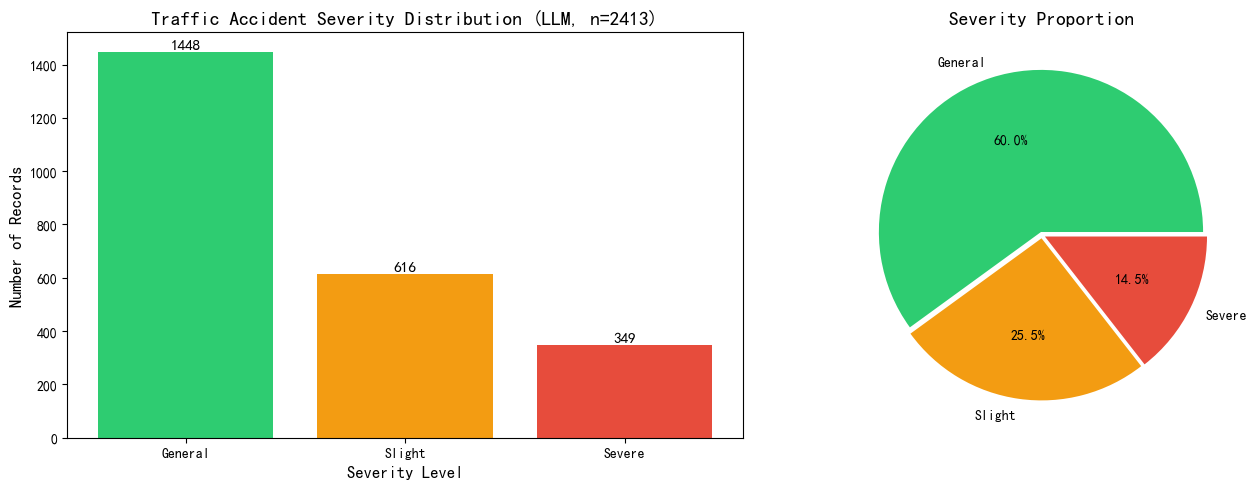


✓ Chart saved: llm_severity_distribution.png


In [50]:
import matplotlib.pyplot as plt

print("\n" + "="*50)
print("Classification Result Statistics")
print("="*50)

stats = result_df['severity_llm'].value_counts()

label_mapping = {
    '一般': 'General',
    '重大': 'Severe',
    '轻微': 'Slight',
    '无伤亡': 'No Casualties' 
}

stats.index = stats.index.map(lambda x: label_mapping.get(x, x))

print(f"\nSeverity distribution:")
for level, count in stats.items():
    percentage = count / len(result_df) * 100
    bar = "█" * int(percentage / 2)
    print(f"  {level}: {count:4d} ({percentage:5.1f}%) {bar}")

# Plot distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = ['#2ecc71', '#f39c12', '#e74c3c']
bars = axes[0].bar(stats.index, stats.values, color=colors[:len(stats)])
axes[0].set_title(
    f'Traffic Accident Severity Distribution (LLM, n={len(result_df)})', 
    fontsize=14, fontweight='bold'
)
axes[0].set_xlabel('Severity Level', fontsize=12)
axes[0].set_ylabel('Number of Records', fontsize=12)

for bar, count in zip(bars, stats.values):
    axes[0].text(
        bar.get_x() + bar.get_width()/2, 
        bar.get_height() + 10, 
        str(count), 
        ha='center', fontsize=11, fontweight='bold'
    )

# Pie chart
axes[1].pie(
    stats.values, 
    labels=stats.index, 
    autopct='%1.1f%%', 
    colors=colors[:len(stats)], 
    explode=[0.02]*len(stats)
)
axes[1].set_title('Severity Proportion', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig(
    'llm_severity_distribution.png', 
    dpi=150, 
    bbox_inches='tight'
)
plt.show()
print("\n✓ Chart saved: llm_severity_distribution.png")

## Step 6: Sample Validation

Randomly sample 3 records from each severity category for manual quality inspection.

In [54]:
print("\n" + "="*50)
print("Sample Validation (Random Selection)")
print("="*50)

# Merge with original text for verification
sample_verify = df[['text_id', 'cleaned_text']].copy()
sample_verify = sample_verify.merge(result_df, on='text_id')

# Show 3 samples per category
for severity in ['重大', '一般', '轻微']:
    print(f"\n【{severity} samples】")
    samples = sample_verify[sample_verify['severity_llm'] == severity].head(3)
    if len(samples) > 0:
        for _, row in samples.iterrows():
            text_preview = str(row['cleaned_text'])[:80] + "..."
            print(f"  • {text_preview}")
    else:
        print(f"  No samples available")


Sample Validation (Random Selection)

【重大 samples】
  • cleaned_text    8月18日晚上，杨某某驾驶湘E6A***小型普通客车行驶至儒林镇白云大道十里树三组路段时，因...
cleaned_text  ...
  • cleaned_text     近日，姜某驾驶小型普通客车在武冈市皇冠世纪城小区行驶过程中，突遇一名小孩坐着滑板车从人行道...
cleaned_text  ...
  • cleaned_text    2024年3月16日，安徽宿州。网约车司机庄某驾驶一辆7座的白色小型客车行至路口，见绿灯刚刚...
cleaned_text  ...

【一般 samples】
  • cleaned_text     2025年3月19日07时07分许，邵阳市北塔区，曾某晚驾驶三轮轻便摩托车搭乘曾某祺、曾某...
cleaned_text  ...
  • cleaned_text     2025年4月13日8时许，黄某驾驶湘A2***7黑色小车行驶至320国道邵东市界岭镇腊树...
cleaned_text  ...
  • cleaned_text     2025年03月07日08时32分许，湖南邵阳，李某驾驶小车行驶至大祥区邵檀路与敏州东路交...
cleaned_text  ...

【轻微 samples】
  • cleaned_text    宁夏回族自治区中宁县，孙某驾驶小客车沿滨河路由南向北行至与枣东路交口处，未按规定让行，与沿枣...
cleaned_text  ...
  • cleaned_text    3月3日，邵阳洞口县，刘某峰驾驶湘AD小车行驶至金塘村与G320线交汇处，左转弯进入G320...
cleaned_text  ...
  • cleaned_text    3月8日，邵阳双清区，一男子骑行电动自行车沿工业街行驶至第二人民医院路段时，一名小孩正在马路...
cleaned_text  ...


## Step 7: Final Report & Export

Export the final classification result and generate a summary report.

In [58]:
# Export final result file
final_output = result_df[['text_id', 'severity_llm']].copy()
final_output.to_csv(
    'LLM_classification_result_final.csv', 
    index=False, 
    encoding='utf-8-sig'
)

raw_stats = result_df['severity_llm'].value_counts()

slight_count = raw_stats.get('轻微', 0)
general_count = raw_stats.get('一般', 0)
severe_count = raw_stats.get('重大', 0)
total_count = len(result_df)

# Generate summary report (100% English with 'Slight')
report = f"""
========================================
Traffic Accident Severity Classification Report (LLM Method)
========================================

Process Time: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}
Data Source: {DATA_PATH}
Model: Zhipu GLM-4

Data Statistics
- Total records: {total_count}
- Successfully processed: {success_count}
- Failed: {failed_count}
- Success rate: {success_count/total_count*100:.1f}%

Severity Distribution
------------------------------
Slight:  {slight_count} records ({slight_count/total_count*100:.1f}%)
General: {general_count} records ({general_count/total_count*100:.1f}%)
Severe:  {severe_count} records ({severe_count/total_count*100:.1f}%)

Output Files
1. LLM_classification_result_final.csv - final classification result
2. llm_classification_results_full.csv - full backup
3. llm_severity_distribution.png - distribution chart

========================================
"""

with open('LLM_Classification_Report.txt', 'w', encoding='utf-8') as f:
    f.write(report)

print("\n" + "="*50)
print("✅ Final Output Files")
print("="*50)
print("\n📁 File list:")
print("1. LLM_classification_result_final.csv - final classification result")
print("2. llm_classification_results_full.csv - full backup")
print("3. llm_severity_distribution.png - distribution chart")
print("4. LLM_Classification_Report.txt - summary report")

print(f"\n📊 Summary:")
print(f"  Total records: {total_count}")
print(f"  Slight:  {slight_count}")
print(f"  General: {general_count}")
print(f"  Severe:  {severe_count}")

print("\n🎉 All processing completed!")


✅ Final Output Files

📁 File list:
1. LLM_classification_result_final.csv - final classification result
2. llm_classification_results_full.csv - full backup
3. llm_severity_distribution.png - distribution chart
4. LLM_Classification_Report.txt - summary report

📊 Summary:
  Total records: 2413
  Slight:  616
  General: 1448
  Severe:  349

🎉 All processing completed!
